# Clasificarea Calității Vinului Roșu
## Wine Quality Dataset — Proces KDD

**Sarcină:** Clasificare binară — vin de calitate bună (quality ≥ 7) vs. slab (quality ≤ 6)  
**Dataset:** [Wine Quality Dataset — Kaggle ]

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, auc,
    confusion_matrix, classification_report
)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("Biblioteci importate cu succes.")
print(f"Random seed setat la {RANDOM_SEED} pentru reproducibilitate.")

Biblioteci importate cu succes.
Random seed setat la 42 pentru reproducibilitate.


---
## 1. Selecția Datelor

Setul de date conține 1.599 de vinuri roșii portugheze (Vinho Verde) cu 11 proprietăți fizico-chimice și un scor de calitate evaluat de experți (3–8).  
Este adecvat pentru clasificare deoarece variabila țintă poate fi binarizată logic, iar toate caracteristicile sunt numerice continue.

**Variabila țintă:** `quality_binary` — 1 dacă quality ≥ 7 (bun), 0 altfel (slab)

In [39]:
df = pd.read_csv('WineQT.csv')
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])

print(f'Dimensiuni: {df.shape}')
df.head()

Dimensiuni: (1143, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [40]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


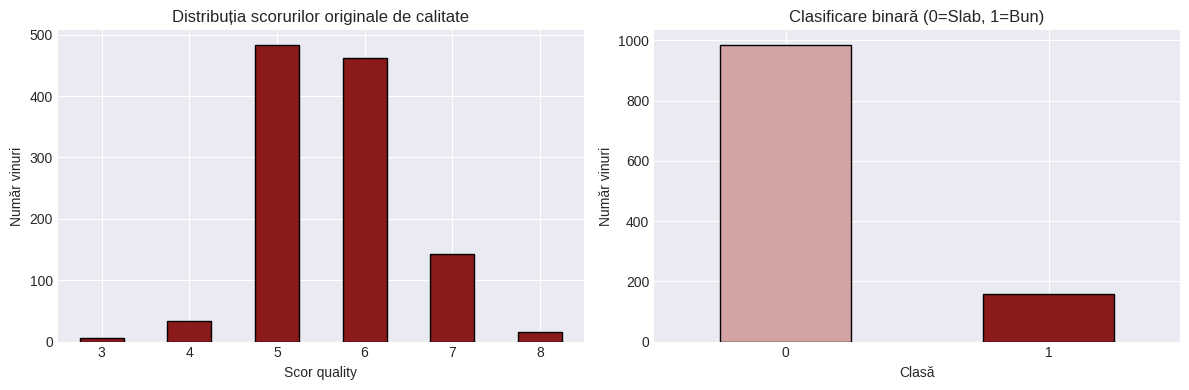

Distribuție absolută:
quality_binary
0    984
1    159
Name: count, dtype: int64

Distribuție procentuală:
quality_binary
0    0.861
1    0.139
Name: proportion, dtype: float64


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['quality'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='#8B1A1A', edgecolor='black')
axes[0].set_title('Distribuția scorurilor originale de calitate')
axes[0].set_xlabel('Scor quality')
axes[0].set_ylabel('Număr vinuri')
axes[0].tick_params(rotation=0)

df['quality_binary'] = (df['quality'] >= 7).astype(int)
df['quality_binary'].value_counts().plot(kind='bar', ax=axes[1], color=['#D4A4A4', '#8B1A1A'], edgecolor='black')
axes[1].set_title('Clasificare binară (0=Slab, 1=Bun)')
axes[1].set_xlabel('Clasă')
axes[1].set_ylabel('Număr vinuri')
axes[1].tick_params(rotation=0)

plt.tight_layout()
plt.show()

print('Distribuție absolută:')
print(df['quality_binary'].value_counts())
print('\nDistribuție procentuală:')
print(df['quality_binary'].value_counts(normalize=True).round(3))

---
## 2. Preprocesarea Datelor



### 2.1 Valori lipsă

Primul pas este verificarea completitudinii datelor. Valorile lipsă pot afecta antrenarea modelelor și trebuie tratate înainte de orice altă operație.


In [42]:
print('Valori lipsă per coloană:')
print(df.isnull().sum())
print(f'\nTotal valori lipsă: {df.isnull().sum().sum()}')

Valori lipsă per coloană:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
quality_binary          0
dtype: int64

Total valori lipsă: 0


### 2.2 Detectarea și tratarea outlierilor

Folosim metoda IQR pentru detectare și Winsorization (clipping la percentilele 5%–95%) pentru tratare, păstrând toate observațiile.

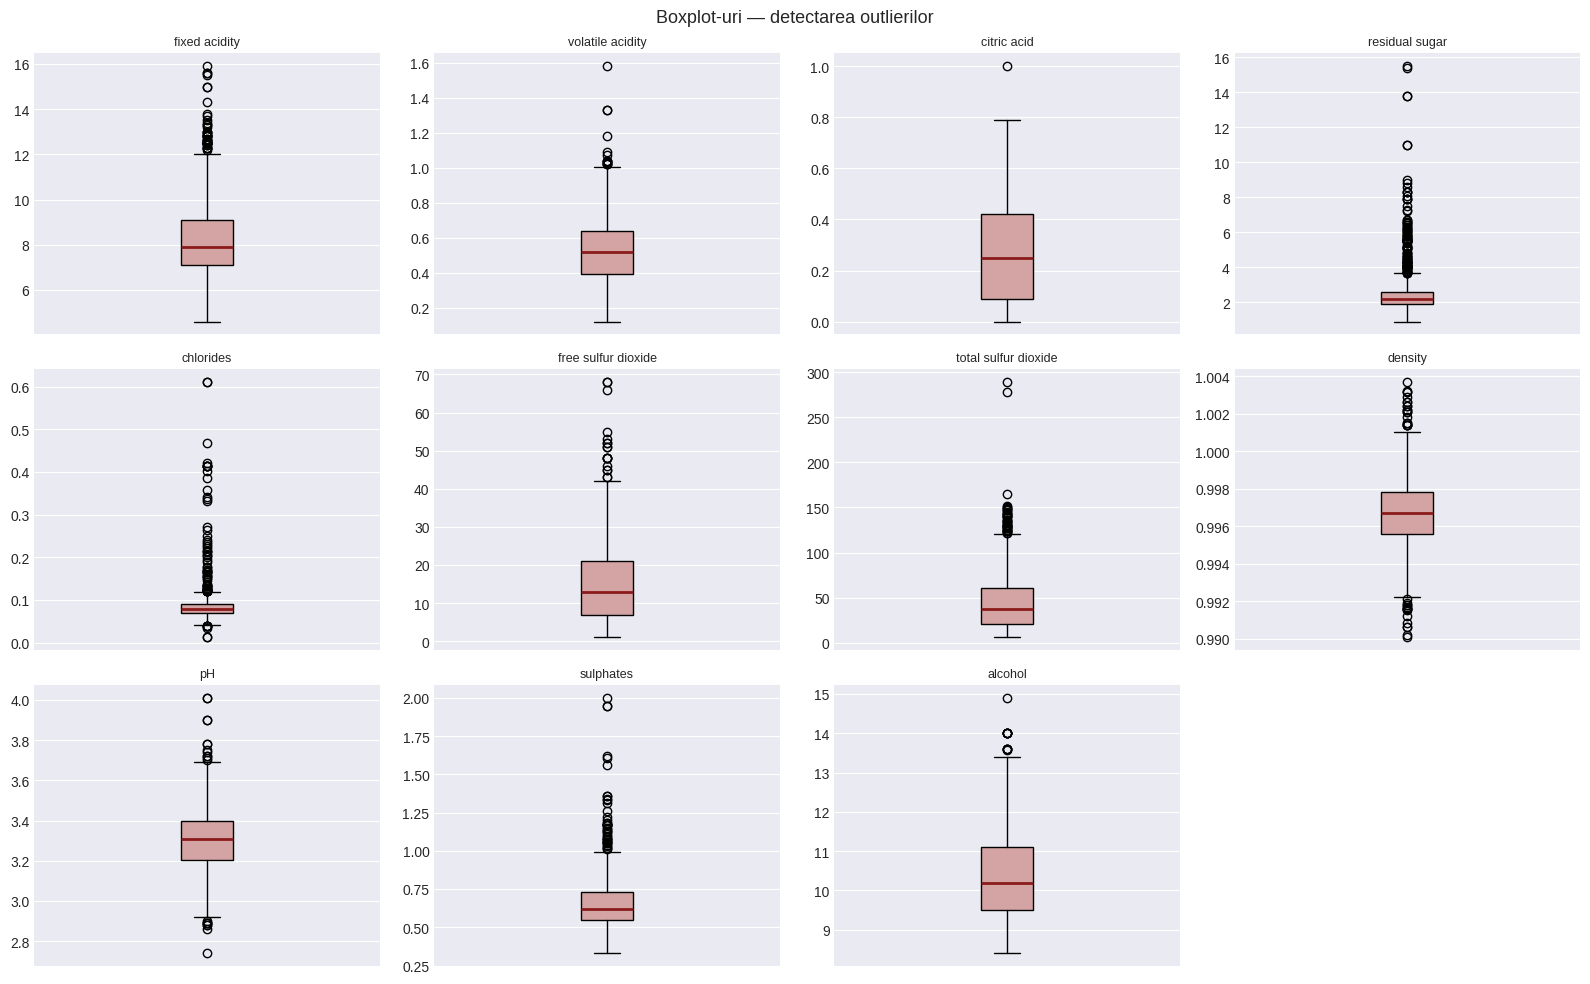

In [43]:
features = [c for c in df.columns if c not in ['quality', 'quality_binary']]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    axes[i].boxplot(df[col], patch_artist=True,
                    boxprops=dict(facecolor='#D4A4A4'),
                    medianprops=dict(color='#8B1A1A', linewidth=2))
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xticks([])

axes[-1].set_visible(False)
plt.suptitle('Boxplot-uri — detectarea outlierilor', fontsize=13)
plt.tight_layout()
plt.show()

In [44]:
for col in features:
    lo, hi = df[col].quantile(0.05), df[col].quantile(0.95)
    df[col] = df[col].clip(lo, hi)

print(f'Winsorization aplicată. Rânduri păstrate: {len(df)}')

Winsorization aplicată. Rânduri păstrate: 1143


### 2.3 Matricea de corelație

Analizăm corelațiile dintre variabile pentru a înțelege ce caracteristici influențează cel mai mult calitatea vinului și dacă există colinearități între predictori.

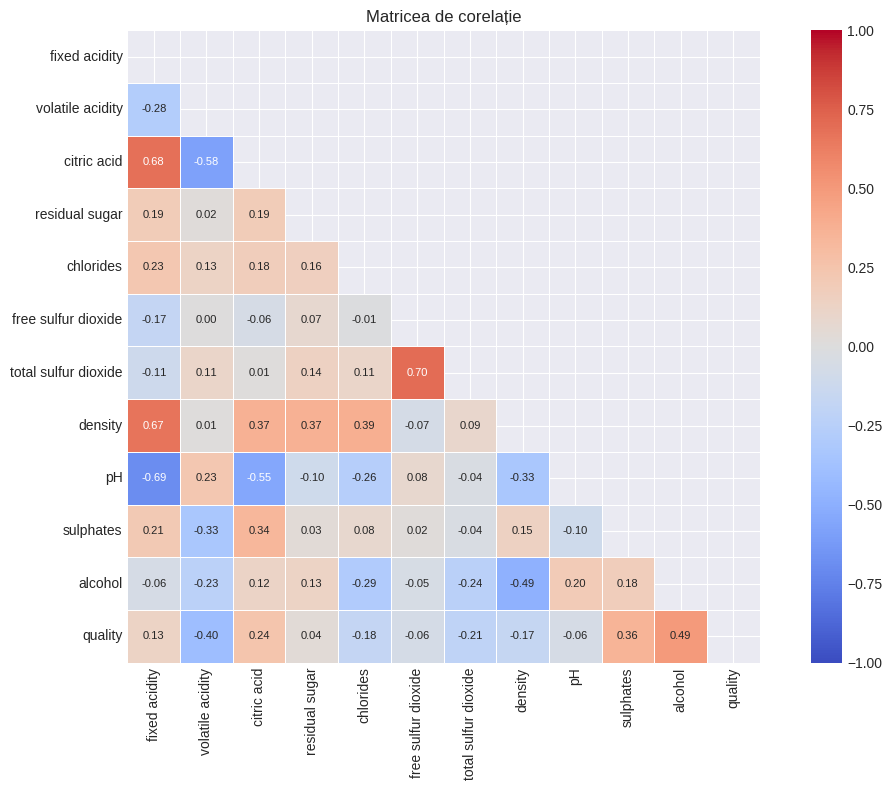


Corelația cu variabila quality (absolut, descrescător):
alcohol                 0.494
volatile acidity        0.403
sulphates               0.357
citric acid             0.242
total sulfur dioxide    0.206
chlorides               0.179
density                 0.171
fixed acidity           0.131
free sulfur dioxide     0.064
pH                      0.058
residual sugar          0.037
Name: quality, dtype: float64


In [45]:
corr_matrix = df[features + ['quality']].corr()

mask = np.zeros_like(corr_matrix, dtype=bool)
mask[np.triu_indices_from(mask)] = True

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f',
            cmap='coolwarm', center=0,
            vmin=-1, vmax=1,
            square=True, linewidths=0.5,
            annot_kws={'size': 8}, ax=ax)
ax.set_title('Matricea de corelație')
plt.tight_layout()
plt.show()

print('\nCorelația cu variabila quality (absolut, descrescător):')
print(corr_matrix['quality'].drop('quality').abs().sort_values(ascending=False).round(3))

---
## 3. Transformarea Datelor

Împărțim datele în 80% train și 20% test, cu stratificare pentru a păstra proporția claselor.  
StandardScaler este antrenat **exclusiv pe setul de train** pentru a preveni data leakage.

In [46]:
X = df[features]
y = df['quality_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'Dimensiuni seturi:')
print(f'   Training: {len(X_train)} instanțe ({len(X_train)/len(X)*100:.1f}%)')
print(f'   Test:     {len(X_test)} instanțe ({len(X_test)/len(X)*100:.1f}%)')
print(f'\nVerificare stratificare:')
print(f'   % Bun în dataset complet: {y.mean()*100:.2f}%')
print(f'   % Bun în train:           {y_train.mean()*100:.2f}%')
print(f'   % Bun în test:            {y_test.mean()*100:.2f}%')

Dimensiuni seturi:
   Training: 914 instanțe (80.0%)
   Test:     229 instanțe (20.0%)

Verificare stratificare:
   % Bun în dataset complet: 13.91%
   % Bun în train:           13.89%
   % Bun în test:            13.97%


---
## 4. Selecția și Antrenarea Modelelor

Comparăm trei algoritmi cu complexitate crescândă:
- **Logistic Regression** — model liniar, linie de bază
- **Random Forest** — ansamblu de arbori (bagging), robust la overfitting
- **Gradient Boosting** — ansamblu secvențial, adesea cel mai performant pe date tabulate

Logistic Regression folosește datele standardizate; arborii nu necesită standardizare.

In [47]:
lr = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED)
lr.fit(X_train_sc, y_train)

X_train_sm = sm.add_constant(X_train_sc)
X_test_sm  = sm.add_constant(X_test_sc)
logit_model = sm.Logit(y_train, X_train_sm)
logit_result = logit_model.fit(disp=0)
print(logit_result.summary())

rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_SEED, n_jobs=-1)
rf.fit(X_train, y_train)

gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=RANDOM_SEED)
gb.fit(X_train, y_train)

print('\nModele antrenate cu succes.')

                           Logit Regression Results                           
Dep. Variable:         quality_binary   No. Observations:                  914
Model:                          Logit   Df Residuals:                      902
Method:                           MLE   Df Model:                           11
Date:                Thu, 04 Jun 2026   Pseudo R-squ.:                  0.3683
Time:                        20:59:33   Log-Likelihood:                -232.72
converged:                       True   LL-Null:                       -368.39
Covariance Type:            nonrobust   LLR p-value:                 9.376e-52
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -3.0193      0.206    -14.644      0.000      -3.423      -2.615
x1             0.2942      0.293      1.004      0.315      -0.280       0.868
x2            -0.5452      0.189     -2.880      0.0

---
## 5. Evaluarea Modelelor

### 5.1 Raport de clasificare

Metricile principale sunt **F1-Score** și **AUC-ROC**, mai robuste decât Accuracy în cazul claselor dezechilibrate (~86% vs ~14%).

In [48]:
models = {
    'Logistic Regression': (lr, X_test_sc, X_train_sc),
    'Random Forest':       (rf, X_test,    X_train),
    'Gradient Boosting':   (gb, X_test,    X_train)
}

results = {}
for name, (model, Xt, Xtr) in models.items():
    yp      = model.predict(Xt)
    ypr     = model.predict_proba(Xt)[:, 1]
    yp_train = model.predict(Xtr)
    results[name] = {'pred': yp, 'proba': ypr, 'pred_train': yp_train}
    print(f'=== {name} ===')
    print('-- Set de test --')
    print(classification_report(y_test, yp, target_names=['Bun (1)', 'Slab (0)']))
    print('-- Set de antrenare --')
    print(classification_report(y_train, yp_train, target_names=['Bun (1)', 'Slab (0)']))


=== Logistic Regression ===
-- Set de test --
              precision    recall  f1-score   support

     Bun (1)       0.90      0.96      0.93       197
    Slab (0)       0.61      0.34      0.44        32

    accuracy                           0.88       229
   macro avg       0.76      0.65      0.69       229
weighted avg       0.86      0.88      0.86       229

-- Set de antrenare --
              precision    recall  f1-score   support

     Bun (1)       0.91      0.96      0.94       787
    Slab (0)       0.64      0.39      0.49       127

    accuracy                           0.89       914
   macro avg       0.77      0.68      0.71       914
weighted avg       0.87      0.89      0.87       914

=== Random Forest ===
-- Set de test --
              precision    recall  f1-score   support

     Bun (1)       0.93      0.97      0.95       197
    Slab (0)       0.74      0.53      0.62        32

    accuracy                           0.91       229
   macro avg       

### 5.2 Tabel comparativ rezumat

Calculăm metricile principale pentru fiecare model și le comparăm într-un tabel. Metrica principală este F1-Score, mai relevantă decât Accuracy în cazul claselor dezechilibrate.

In [49]:
summary = {}
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r['proba'])
    roc_auc = auc(fpr, tpr)
    summary[name] = {
        'Accuracy':  round(accuracy_score(y_test, r['pred']), 4),
        'Precision': round(precision_score(y_test, r['pred'], zero_division=0), 4),
        'Recall':    round(recall_score(y_test, r['pred'], zero_division=0), 4),
        'F1-Score':  round(f1_score(y_test, r['pred'], zero_division=0), 4),
        'AUC-ROC':   round(roc_auc, 4)
    }
    results[name]['fpr'] = fpr
    results[name]['tpr'] = tpr
    results[name]['auc'] = roc_auc

print(pd.DataFrame(summary).T)

                     Accuracy  Precision  Recall  F1-Score  AUC-ROC
Logistic Regression    0.8777     0.6111  0.3438    0.4400   0.8536
Random Forest          0.9083     0.7391  0.5312    0.6182   0.9172
Gradient Boosting      0.9039     0.6667  0.6250    0.6452   0.8917


### 5.3 Matricele de confuzie

Matricea de confuzie arată distribuția predicțiilor corecte și greșite pentru fiecare model. Clasa pozitivă (Bun) este plasată pe primul rând.

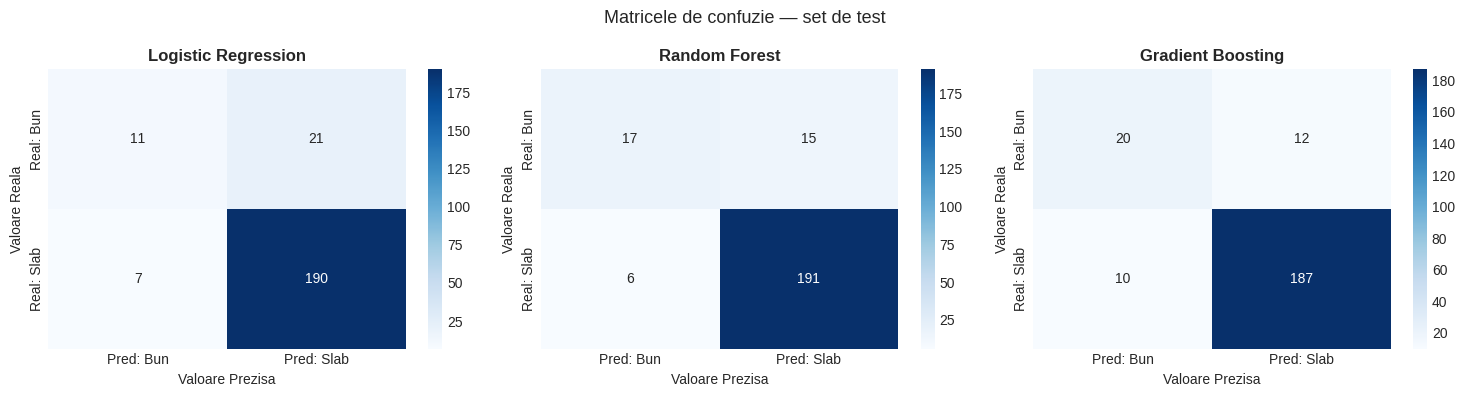

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r['pred'], labels=[1, 0])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred: Bun', 'Pred: Slab'],
                yticklabels=['Real: Bun', 'Real: Slab'])
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Valoare Reala')
    ax.set_xlabel('Valoare Prezisa')

plt.suptitle('Matricele de confuzie — set de test', fontsize=13)
plt.tight_layout()
plt.show()


### 5.4 Curbele ROC

Curbele ROC vizualizează performanța modelelor la diferite praguri de clasificare. Cu cât curba e mai aproape de colțul stânga-sus, cu atât modelul discriminează mai bine între clase.

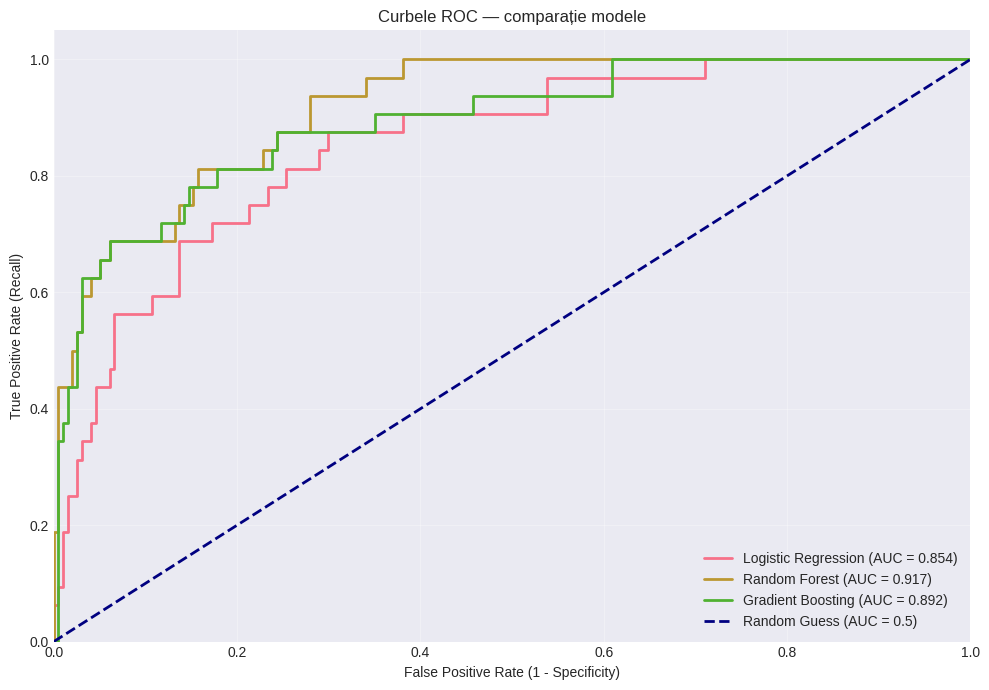

In [51]:
plt.figure(figsize=(10, 7))

for name, r in results.items():
    plt.plot(r['fpr'], r['tpr'],
             label=f"{name} (AUC = {r['auc']:.3f})",
             linewidth=2)

plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',
         label='Random Guess (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Curbele ROC — comparație modele')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 5.5 Importanța caracteristicilor — Random Forest

Random Forest calculează automat importanța fiecărei caracteristici prin reducerea impurității Gini. Valorile sumează la 1 — cu cât e mai mare, cu atât caracteristica contribuie mai mult la clasificare.

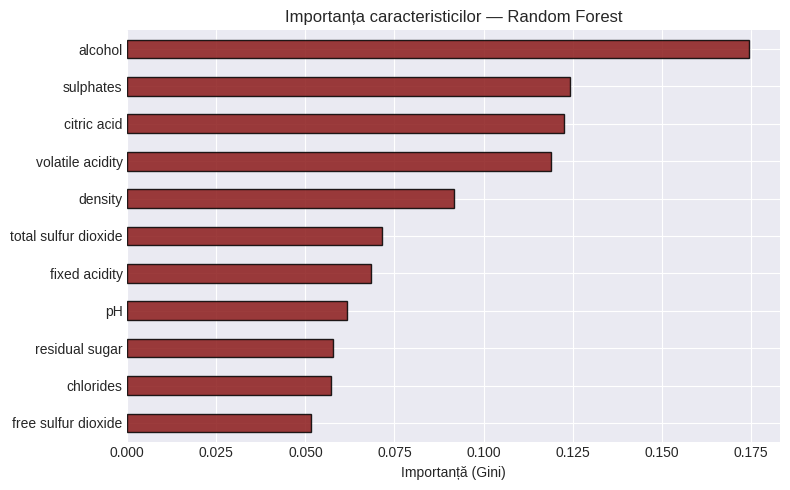

In [52]:
importances = pd.Series(rf.feature_importances_, index=features).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind='barh', ax=ax, color='#8B1A1A', edgecolor='black', alpha=0.85)
ax.set_title('Importanța caracteristicilor — Random Forest')
ax.set_xlabel('Importanță (Gini)')
plt.tight_layout()
plt.show()

### 5.6 Validare încrucișată (Cross-Validation)

Aplicăm cross-validation pe modelul cel mai performant pentru a confirma că rezultatele sunt stabile și nu depind de împărțirea train/test.

In [53]:
best_name = max(summary, key=lambda k: summary[k]['F1-Score'])
best_model = {'Logistic Regression': lr, 'Random Forest': rf, 'Gradient Boosting': gb}[best_name]
X_cv = X_train_sc if best_name == 'Logistic Regression' else X_train

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)

cv_scores = cross_val_score(
    best_model, X_cv, y_train,
    cv=cv, scoring='accuracy'
)

print(f'Cross-validation pentru: {best_name}')
print(f'Acuratețe pe cele 10 fold-uri: {cv_scores.round(4)}')
print(f'Acuratete medie CV:  {cv_scores.mean():.4f}')
print(f'Deviație standard CV: {cv_scores.std():.4f}')

Cross-validation pentru: Gradient Boosting
Acuratețe pe cele 10 fold-uri: [0.8913 0.8804 0.8804 0.9457 0.9121 0.9011 0.8791 0.8791 0.9231 0.9231]
Acuratete medie CV:  0.9015
Deviație standard CV: 0.0223


### 5.7 Learning Curve

Learning curve arata cum evolueaza eroarea modelului (1 - F1-Score) in functie de numarul de exemple de antrenare. Daca cele doua curbe (eroare antrenare si eroare validare) converg si sunt apropiate, modelul generalizeaza bine. O eroare de antrenare mult mai mica decat eroarea de validare indica overfitting.

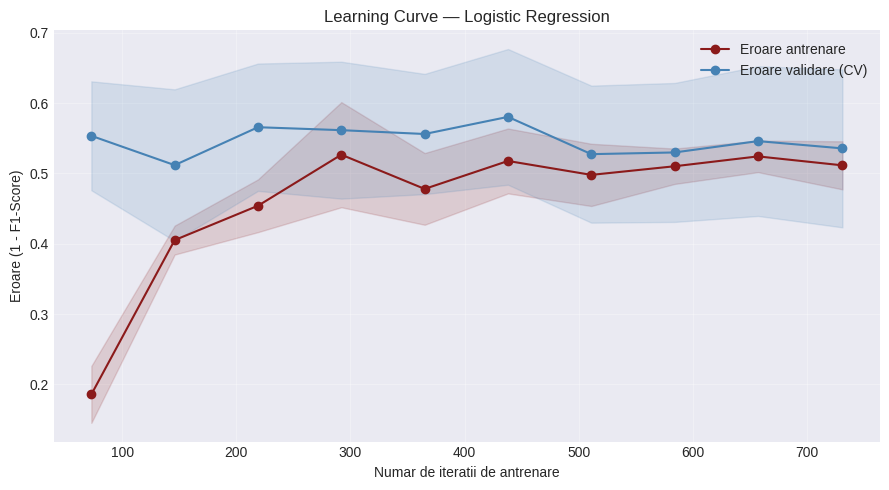

Eroare antrenare la final: 0.5116
Eroare validare  la final: 0.5357
Diferenta: 0.0241


In [54]:
from sklearn.model_selection import learning_curve

lr_lc = LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED)

train_sizes, train_scores, val_scores = learning_curve(
    lr_lc, X_train_sc, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED),
    train_sizes=np.linspace(0.1, 1.0, 10),
    scoring='f1',
    n_jobs=-1
)

train_err_mean = 1 - train_scores.mean(axis=1)
train_err_std  = train_scores.std(axis=1)
val_err_mean   = 1 - val_scores.mean(axis=1)
val_err_std    = val_scores.std(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_err_mean, 'o-', color='#8B1A1A', label='Eroare antrenare')
plt.fill_between(train_sizes,
                 train_err_mean - train_err_std,
                 train_err_mean + train_err_std,
                 alpha=0.15, color='#8B1A1A')
plt.plot(train_sizes, val_err_mean, 'o-', color='steelblue', label='Eroare validare (CV)')
plt.fill_between(train_sizes,
                 val_err_mean - val_err_std,
                 val_err_mean + val_err_std,
                 alpha=0.15, color='steelblue')
plt.xlabel('Numar de iteratii de antrenare')
plt.ylabel('Eroare (1 - F1-Score)')
plt.title('Learning Curve — Logistic Regression')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Eroare antrenare la final: {train_err_mean[-1]:.4f}')
print(f'Eroare validare  la final: {val_err_mean[-1]:.4f}')
print(f'Diferenta: {abs(train_err_mean[-1] - val_err_mean[-1]):.4f}')


---
## 6. Concluzii

### Modelul câștigător și interpretarea rezultatelor

In [55]:
print(f'Cel mai performant model (după F1-Score): {best_name}')
print()
print('Raport de clasificare final pe setul de test:')
print(classification_report(y_test, results[best_name]['pred'],
                             target_names=['Slab (0)', 'Bun (1)']))

Cel mai performant model (după F1-Score): Gradient Boosting

Raport de clasificare final pe setul de test:
              precision    recall  f1-score   support

    Slab (0)       0.94      0.95      0.94       197
     Bun (1)       0.67      0.62      0.65        32

    accuracy                           0.90       229
   macro avg       0.80      0.79      0.79       229
weighted avg       0.90      0.90      0.90       229



Modelele de ansamblu (Random Forest, Gradient Boosting) depășesc Logistic Regression pe toate metricile, confirmând că relația dintre proprietățile chimice și calitatea vinului este **neliniară**.

Cele mai importante caracteristici predictive sunt **alcoolul**, **aciditatea volatilă** și **sulfații** — consistent cu literatura de specialitate din domeniul oenologiei.

**Limitări:** Dezechilibrul de clase (~86% slab vs ~14% bun) limitează Recall-ul pe clasa minoritară. Setul de date este limitat la o singură regiune (Vinho Verde, Portugalia), ceea ce poate afecta generalizarea.

**Aplicații potențiale:** Control calitate automatizat în crame, asistență pentru enologi în ajustarea parametrilor de fermentare.